Random Forest Model for Hardness Prediction

Dataset Information
Samples  : 500
Target   : Hv
Features : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']

Train-Test Split
Training samples : 400
Testing samples  : 100

Hyperparameter Optimization
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best Hyperparameters:
n_estimators        : 800
min_samples_split   : 2
min_samples_leaf    : 2
max_features        : 1.0
max_depth           : 10
bootstrap           : True

Best CV RMSE: 62.987 Hv

Model Performance

Training Set
R2   : 0.9823
RMSE : 29.906 Hv
MAE  : 21.713 Hv

Testing Set
R2   : 0.8660
RMSE : 74.637 Hv
MAE  : 49.434 Hv


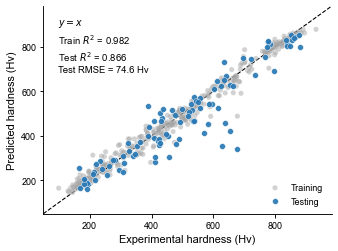


Completed

Generated Files:
1. RF_Parity_Plot.png
2. RF_Train_Test_Predictions.xlsx
3. RF_Hyperparameter_Search.csv
4. RF_Hardness_Model.joblib


In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    KFold,
)
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)


# ============================================================
# 1. Settings
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_ITER = 40
CV_FOLDS = 5

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
DATA_FILE = BASE_DIR / "Data.xlsx"

# Outputs
MODEL_FILE = BASE_DIR / "RF_Hardness_Model.joblib"
PREDICTION_FILE = BASE_DIR / "RF_Train_Test_Predictions.xlsx"
SEARCH_FILE = BASE_DIR / "RF_Hyperparameter_Search.csv"
FIGURE_FILE = BASE_DIR / "RF_Parity_Plot.png"


# ============================================================
# 2. Load data
# ============================================================

data = pd.read_excel(DATA_FILE)

# First column = target
target_name = data.columns[0]

# Remaining columns = input features
feature_names = list(data.columns[1:])


# Remove rows containing missing values
if data.isnull().values.any():

    print("Warning: Missing values detected.")
    print(data.isnull().sum())

    data = data.dropna().reset_index(drop=True)


X = data[feature_names]
y = data[target_name]


print("=" * 60)
print("Dataset Information")
print("=" * 60)

print(f"Samples  : {len(data)}")
print(f"Target   : {target_name}")
print(f"Features : {feature_names}")


# ============================================================
# 3. Train-test split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)


print("\n" + "=" * 60)
print("Train-Test Split")
print("=" * 60)

print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")


# ============================================================
# 4. Random Forest and hyperparameter optimization
# ============================================================

rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


param_distributions = {

    "n_estimators": [
        200,
        300,
        400,
        500,
        600,
        700,
        800,
        900,
        1000,
        1200,
    ],

    "max_depth": [
        None,
        5,
        10,
        15,
        20,
        30,
        40,
    ],

    "min_samples_split": [
        2,
        4,
        6,
        8,
        10,
    ],

    "min_samples_leaf": [
        1,
        2,
        3,
        4,
        5,
    ],

    "max_features": [
        "sqrt",
        "log2",
        0.5,
        0.7,
        1.0,
    ],

    "bootstrap": [
        True,
        False,
    ],
}


cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)


random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
    refit=True,
)


print("\n" + "=" * 60)
print("Hyperparameter Optimization")
print("=" * 60)


random_search.fit(
    X_train,
    y_train,
)


best_model = random_search.best_estimator_

best_cv_rmse = np.sqrt(
    -random_search.best_score_
)


print("\nBest Hyperparameters:")

for parameter, value in random_search.best_params_.items():
    print(f"{parameter:20s}: {value}")


print(
    f"\nBest CV RMSE: "
    f"{best_cv_rmse:.3f} Hv"
)


# ============================================================
# 5. Model evaluation
# ============================================================

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)


def calculate_metrics(y_true, y_pred):

    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
    }


train_metrics = calculate_metrics(
    y_train,
    y_train_pred,
)

test_metrics = calculate_metrics(
    y_test,
    y_test_pred,
)


print("\n" + "=" * 60)
print("Model Performance")
print("=" * 60)

print("\nTraining Set")

print(
    f"R2   : "
    f"{train_metrics['R2']:.4f}"
)

print(
    f"RMSE : "
    f"{train_metrics['RMSE']:.3f} Hv"
)

print(
    f"MAE  : "
    f"{train_metrics['MAE']:.3f} Hv"
)


print("\nTesting Set")

print(
    f"R2   : "
    f"{test_metrics['R2']:.4f}"
)

print(
    f"RMSE : "
    f"{test_metrics['RMSE']:.3f} Hv"
)

print(
    f"MAE  : "
    f"{test_metrics['MAE']:.3f} Hv"
)


# ============================================================
# 6. Save train-test predictions
# ============================================================

train_results = X_train.copy()

train_results["Actual_Hv"] = y_train.to_numpy()
train_results["Predicted_Hv"] = y_train_pred
train_results["Dataset"] = "Train"


test_results = X_test.copy()

test_results["Actual_Hv"] = y_test.to_numpy()
test_results["Predicted_Hv"] = y_test_pred
test_results["Dataset"] = "Test"


prediction_results = pd.concat(
    [
        train_results,
        test_results,
    ],
    ignore_index=True,
)


prediction_results.to_excel(
    PREDICTION_FILE,
    index=False,
)


# ============================================================
# 7. Parity plot
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 9,
    "axes.labelsize": 11,
    "axes.linewidth": 0.9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})


fig, ax = plt.subplots(
    figsize=(5.2, 3.6)
)


# Training data
ax.scatter(
    y_train,
    y_train_pred,
    s=26,
    alpha=0.50,
    facecolor="#A6A6A6",
    edgecolor="none",
    label="Training",
    zorder=2,
)


# Testing data
ax.scatter(
    y_test,
    y_test_pred,
    s=34,
    alpha=0.92,
    facecolor="#2878B5",
    edgecolor="white",
    linewidth=0.45,
    label="Testing",
    zorder=3,
)


# Common axis range
all_actual = np.concatenate(
    [
        y_train.to_numpy(),
        y_test.to_numpy(),
    ]
)

all_predicted = np.concatenate(
    [
        y_train_pred,
        y_test_pred,
    ]
)


plot_min = min(
    all_actual.min(),
    all_predicted.min(),
)

plot_max = max(
    all_actual.max(),
    all_predicted.max(),
)


padding = (
    plot_max
    - plot_min
) * 0.06


plot_min -= padding
plot_max += padding


# y = x reference line
ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    "--",
    color="black",
    linewidth=1.1,
    zorder=1,
)


ax.set_xlim(
    plot_min,
    plot_max,
)

ax.set_ylim(
    plot_min,
    plot_max,
)


# Rectangular layout suitable for presentation
ax.set_box_aspect(0.72)


ax.set_xlabel(
    "Experimental hardness (Hv)"
)

ax.set_ylabel(
    "Predicted hardness (Hv)"
)


# Nature-style axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    direction="out",
    width=0.9,
    length=3.5,
)


# Performance information
performance_text = (
    "$y=x$\n"
    f"Train $R^2$ = {train_metrics['R2']:.3f}\n"
    f"Test $R^2$ = {test_metrics['R2']:.3f}\n"
    f"Test RMSE = {test_metrics['RMSE']:.1f} Hv"
)


ax.text(
    0.05,
    0.95,
    performance_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9.5,
    linespacing=1.3,
)


ax.legend(
    loc="lower right",
    frameon=False,
)


ax.grid(False)

plt.tight_layout()


plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 8. Save hyperparameter search results
# ============================================================

search_results = pd.DataFrame(
    random_search.cv_results_
)

search_results = search_results.sort_values(
    "rank_test_score"
)


search_results.to_csv(
    SEARCH_FILE,
    index=False,
)


# ============================================================
# 9. Train final model using the complete dataset
# ============================================================

final_model = RandomForestRegressor(
    **random_search.best_params_,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


final_model.fit(
    X,
    y,
)


# ============================================================
# 10. Save final model
# ============================================================

model_package = {

    "model": final_model,

    "features": feature_names,

    "target": target_name,

    "best_params": random_search.best_params_,

    "cv_rmse": best_cv_rmse,

    "random_state": RANDOM_STATE,
}


joblib.dump(
    model_package,
    MODEL_FILE,
)


# ============================================================
# 11. Summary
# ============================================================

print("\n" + "=" * 60)
print("Completed")
print("=" * 60)

print("\nGenerated Files:")

print(
    f"1. {FIGURE_FILE.name}"
)

print(
    f"2. {PREDICTION_FILE.name}"
)

print(
    f"3. {SEARCH_FILE.name}"
)

print(
    f"4. {MODEL_FILE.name}"
)

Genetic Algorithm for Alloy Composition Optimization

In [2]:
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd


# ============================================================
# 1. Settings
# ============================================================

RANDOM_STATE = 42

POPULATION_SIZE = 300
N_GENERATIONS = 150

ELITE_SIZE = 20
TOURNAMENT_SIZE = 3

CROSSOVER_RATE = 0.85
MUTATION_RATE = 0.30
MUTATION_STEP = 3

TOP_N = 1000

# Number of feasible compositions in the full 1 at.% design space
DESIGN_SPACE_SIZE = 1_224_117


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
MODEL_FILE = BASE_DIR / "RF_Hardness_Model.joblib"

# Outputs
EXPLORED_FILE = BASE_DIR / "GA_Explored_Candidates.csv"
TOP_CANDIDATES_FILE = BASE_DIR / "GA_Top1000_Candidates.xlsx"


# ============================================================
# 2. Load trained Random Forest model
# ============================================================

model_package = joblib.load(MODEL_FILE)

model = model_package["model"]
feature_names = model_package["features"]
target_name = model_package["target"]


print("=" * 65)
print("Genetic Algorithm Optimization")
print("=" * 65)

print(f"Target   : {target_name}")
print(f"Features : {feature_names}")


# ============================================================
# 3. Composition space
# ============================================================

GA_FEATURES = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


# Composition constraints:
#
# 15 < Al < 47  -> 16–46
# 5  < Co < 22  -> 6–21
# 6  < Cr < 34  -> 7–33
# 5  < Cu < 16  -> 6–15
# 5  < Fe < 31  -> 6–30
# 5  < Ni < 22  -> 6–21
#
# Al + Co + Cr + Cu + Fe + Ni = 100 at.%

LOWER_BOUNDS = np.array(
    [16, 6, 7, 6, 6, 6],
    dtype=int,
)

UPPER_BOUNDS = np.array(
    [46, 21, 33, 15, 30, 21],
    dtype=int,
)


# Check consistency with RF model
if set(feature_names) != set(GA_FEATURES):
    raise ValueError(
        "GA composition features do not match "
        "the Random Forest model features."
    )


# Random number generator
rng = np.random.default_rng(
    RANDOM_STATE
)


# ============================================================
# 4. Repair composition
# ============================================================

def repair_individual(individual):
    """
    Repair a composition so that:

    1. All elemental contents remain within their bounds.
    2. All compositions remain integers.
    3. The total composition equals 100 at.%.
    """

    individual = np.asarray(
        individual,
        dtype=int,
    ).copy()


    individual = np.clip(
        individual,
        LOWER_BOUNDS,
        UPPER_BOUNDS,
    )


    difference = 100 - individual.sum()


    # Total < 100: increase eligible elements
    while difference > 0:

        available = np.where(
            individual < UPPER_BOUNDS
        )[0]

        if len(available) == 0:
            raise RuntimeError(
                "Unable to repair composition."
            )

        index = rng.choice(
            available
        )

        individual[index] += 1
        difference -= 1


    # Total > 100: decrease eligible elements
    while difference < 0:

        available = np.where(
            individual > LOWER_BOUNDS
        )[0]

        if len(available) == 0:
            raise RuntimeError(
                "Unable to repair composition."
            )

        index = rng.choice(
            available
        )

        individual[index] -= 1
        difference += 1


    return individual


# ============================================================
# 5. Generate one feasible random alloy
# ============================================================

def create_random_individual():
    """Generate one feasible alloy composition."""

    while True:

        al = rng.integers(16, 47)
        co = rng.integers(6, 22)
        cr = rng.integers(7, 34)
        cu = rng.integers(6, 16)
        fe = rng.integers(6, 31)

        ni = 100 - (
            al
            + co
            + cr
            + cu
            + fe
        )


        if 6 <= ni <= 21:

            return np.array(
                [
                    al,
                    co,
                    cr,
                    cu,
                    fe,
                    ni,
                ],
                dtype=int,
            )


# ============================================================
# 6. Generate initial population
# ============================================================

def create_initial_population():
    """Generate a unique initial GA population."""

    population = []
    existing = set()


    while len(population) < POPULATION_SIZE:

        individual = create_random_individual()
        key = tuple(individual)


        if key not in existing:

            population.append(
                individual
            )

            existing.add(
                key
            )


    return np.asarray(
        population,
        dtype=int,
    )


# ============================================================
# 7. Fitness evaluation
# ============================================================

fitness_cache = {}


def evaluate_population(population):
    """
    Predict hardness using the trained Random Forest model.

    Previously evaluated compositions are retrieved from cache
    to avoid repeated predictions.
    """

    fitness = np.zeros(
        len(population),
        dtype=float,
    )


    new_indices = []
    new_candidates = []


    for index, individual in enumerate(population):

        key = tuple(individual)


        if key in fitness_cache:

            fitness[index] = fitness_cache[key]

        else:

            new_indices.append(
                index
            )

            new_candidates.append(
                individual
            )


    if new_candidates:

        candidate_df = pd.DataFrame(
            new_candidates,
            columns=GA_FEATURES,
        )


        # Ensure the same feature order used during RF training
        candidate_df = candidate_df[
            feature_names
        ]


        predicted_hv = model.predict(
            candidate_df
        )


        for index, hv in zip(
            new_indices,
            predicted_hv,
        ):

            fitness[index] = hv

            key = tuple(
                population[index]
            )

            fitness_cache[key] = float(
                hv
            )


    return fitness


# ============================================================
# 8. Tournament selection
# ============================================================

def tournament_selection(
    population,
    fitness,
):
    """Select one parent using tournament selection."""

    candidate_indices = rng.choice(
        len(population),
        size=TOURNAMENT_SIZE,
        replace=False,
    )


    winner_index = candidate_indices[
        np.argmax(
            fitness[candidate_indices]
        )
    ]


    return population[
        winner_index
    ].copy()


# ============================================================
# 9. Crossover
# ============================================================

def crossover(
    parent_1,
    parent_2,
):
    """Uniform crossover followed by composition repair."""

    if rng.random() > CROSSOVER_RATE:

        return (
            parent_1.copy(),
            parent_2.copy(),
        )


    mask = (
        rng.random(
            len(parent_1)
        )
        < 0.5
    )


    child_1 = np.where(
        mask,
        parent_1,
        parent_2,
    )


    child_2 = np.where(
        mask,
        parent_2,
        parent_1,
    )


    child_1 = repair_individual(
        child_1
    )

    child_2 = repair_individual(
        child_2
    )


    return child_1, child_2


# ============================================================
# 10. Mutation
# ============================================================

def mutate(individual):
    """
    Transfer 1–MUTATION_STEP at.% between two elements.
    """

    child = individual.copy()


    if rng.random() < MUTATION_RATE:

        index_1, index_2 = rng.choice(
            len(child),
            size=2,
            replace=False,
        )


        step = rng.integers(
            1,
            MUTATION_STEP + 1,
        )


        if rng.random() < 0.5:

            child[index_1] += step
            child[index_2] -= step

        else:

            child[index_1] -= step
            child[index_2] += step


        child = repair_individual(
            child
        )


    return child


# ============================================================
# 11. Initialize GA
# ============================================================

print("\nGA Parameters")

print(
    f"Population size       : "
    f"{POPULATION_SIZE}"
)

print(
    f"Generations           : "
    f"{N_GENERATIONS}"
)

print(
    f"Elite size            : "
    f"{ELITE_SIZE}"
)

print(
    f"Tournament size       : "
    f"{TOURNAMENT_SIZE}"
)

print(
    f"Crossover rate        : "
    f"{CROSSOVER_RATE}"
)

print(
    f"Mutation rate         : "
    f"{MUTATION_RATE}"
)

print(
    f"Mutation step         : "
    f"1–{MUTATION_STEP} at.%"
)


population = create_initial_population()

start_time = perf_counter()


# ============================================================
# 12. Main GA loop
# ============================================================

for generation in range(
    1,
    N_GENERATIONS + 1,
):

    # --------------------------------------------------------
    # Evaluate current population
    # --------------------------------------------------------

    fitness = evaluate_population(
        population
    )


    # --------------------------------------------------------
    # Sort from high to low predicted hardness
    # --------------------------------------------------------

    order = np.argsort(
        fitness
    )[::-1]


    population = population[
        order
    ]

    fitness = fitness[
        order
    ]


    current_best = fitness[0]
    current_mean = fitness.mean()


    print(
        f"Generation "
        f"{generation:3d}/{N_GENERATIONS} | "
        f"Best Hv {current_best:8.2f} | "
        f"Mean Hv {current_mean:8.2f} | "
        f"Unique {len(fitness_cache):6d}"
    )


    # --------------------------------------------------------
    # Create next generation
    # --------------------------------------------------------

    new_population = [
        individual.copy()
        for individual in population[
            :ELITE_SIZE
        ]
    ]


    while len(new_population) < POPULATION_SIZE:

        parent_1 = tournament_selection(
            population,
            fitness,
        )

        parent_2 = tournament_selection(
            population,
            fitness,
        )


        child_1, child_2 = crossover(
            parent_1,
            parent_2,
        )


        child_1 = mutate(
            child_1
        )

        child_2 = mutate(
            child_2
        )


        new_population.append(
            child_1
        )


        if len(new_population) < POPULATION_SIZE:

            new_population.append(
                child_2
            )


    population = np.asarray(
        new_population[
            :POPULATION_SIZE
        ],
        dtype=int,
    )


# ============================================================
# 13. Evaluate final population
# ============================================================

evaluate_population(
    population
)


# ============================================================
# 14. Collect all explored candidates
# ============================================================

candidate_rows = [
    list(composition)
    + [predicted_hv]

    for composition, predicted_hv
    in fitness_cache.items()
]


explored_candidates = pd.DataFrame(
    candidate_rows,
    columns=(
        GA_FEATURES
        + ["Predicted_Hv"]
    ),
)


explored_candidates = (
    explored_candidates
    .sort_values(
        "Predicted_Hv",
        ascending=False,
    )
    .reset_index(drop=True)
)


explored_candidates.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(explored_candidates) + 1,
    ),
)


# ============================================================
# 15. Best alloy
# ============================================================

best_candidate = explored_candidates.iloc[
    0
]


best_predicted_hv = best_candidate[
    "Predicted_Hv"
]


# ============================================================
# 16. Save results
# ============================================================

explored_candidates.to_csv(
    EXPLORED_FILE,
    index=False,
)


top_candidates = explored_candidates.head(
    TOP_N
).copy()


top_candidates.to_excel(
    TOP_CANDIDATES_FILE,
    index=False,
)


# ============================================================
# 17. Final summary
# ============================================================

elapsed_time = (
    perf_counter()
    - start_time
)


n_unique = len(
    explored_candidates
)


evaluation_fraction = (
    n_unique
    / DESIGN_SPACE_SIZE
    * 100
)


print("\n" + "=" * 65)
print("GA Optimization Completed")
print("=" * 65)

print(
    f"Unique candidates evaluated : "
    f"{n_unique:,}"
)

print(
    f"Full design-space size      : "
    f"{DESIGN_SPACE_SIZE:,}"
)

print(
    f"Fraction evaluated          : "
    f"{evaluation_fraction:.4f}%"
)

print(
    f"Best predicted Hv           : "
    f"{best_predicted_hv:.3f}"
)

print(
    f"Calculation time            : "
    f"{elapsed_time:.2f} s"
)


print("\nBest Composition:")

for element in GA_FEATURES:

    print(
        f"{element:2s} : "
        f"{int(best_candidate[element])} at.%"
    )


print("\nGenerated Files:")

print(
    f"1. {EXPLORED_FILE.name}"
)

print(
    f"2. {TOP_CANDIDATES_FILE.name}"
)


print("\n" + "=" * 65)
print("Top 20 GA Candidates")
print("=" * 65)

print(
    top_candidates
    .head(20)
    .to_string(index=False)
)

Genetic Algorithm Optimization
Target   : Hv
Features : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']

GA Parameters
Population size       : 300
Generations           : 150
Elite size            : 20
Tournament size       : 3
Crossover rate        : 0.85
Mutation rate         : 0.3
Mutation step         : 1–3 at.%
Generation   1/150 | Best Hv   800.80 | Mean Hv   596.89 | Unique    300
Generation   2/150 | Best Hv   800.80 | Mean Hv   664.47 | Unique    540
Generation   3/150 | Best Hv   805.33 | Mean Hv   710.69 | Unique    777
Generation   4/150 | Best Hv   813.18 | Mean Hv   740.69 | Unique   1010
Generation   5/150 | Best Hv   830.49 | Mean Hv   763.07 | Unique   1239
Generation   6/150 | Best Hv   830.49 | Mean Hv   775.69 | Unique   1454
Generation   7/150 | Best Hv   831.94 | Mean Hv   787.70 | Unique   1669
Generation   8/150 | Best Hv   832.45 | Mean Hv   796.22 | Unique   1863
Generation   9/150 | Best Hv   832.45 | Mean Hv   812.65 | Unique   1986
Generation  10/150 | Best Hv   832.4

Generation 108/150 | Best Hv   832.45 | Mean Hv   825.44 | Unique   2351
Generation 109/150 | Best Hv   832.45 | Mean Hv   824.99 | Unique   2352
Generation 110/150 | Best Hv   832.45 | Mean Hv   828.31 | Unique   2352
Generation 111/150 | Best Hv   832.45 | Mean Hv   824.84 | Unique   2353
Generation 112/150 | Best Hv   832.45 | Mean Hv   824.26 | Unique   2355
Generation 113/150 | Best Hv   832.45 | Mean Hv   824.90 | Unique   2357
Generation 114/150 | Best Hv   832.45 | Mean Hv   826.88 | Unique   2360
Generation 115/150 | Best Hv   832.45 | Mean Hv   828.22 | Unique   2360
Generation 116/150 | Best Hv   832.45 | Mean Hv   825.23 | Unique   2361
Generation 117/150 | Best Hv   832.45 | Mean Hv   825.80 | Unique   2361
Generation 118/150 | Best Hv   832.45 | Mean Hv   825.15 | Unique   2361
Generation 119/150 | Best Hv   832.45 | Mean Hv   826.13 | Unique   2361
Generation 120/150 | Best Hv   832.45 | Mean Hv   827.04 | Unique   2361
Generation 121/150 | Best Hv   832.45 | Mean Hv   8

Composition Distribution of GA-Explored Candidates

GA Composition Distribution
GA candidates : 2,370
Elements      : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']


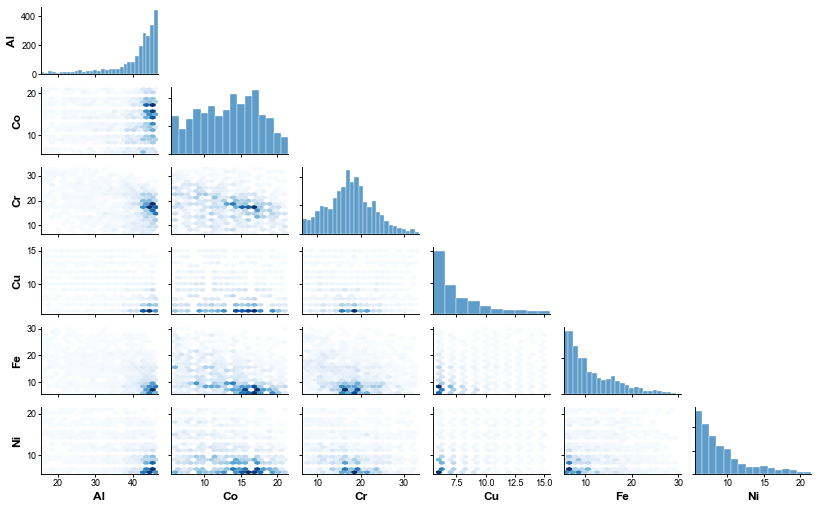


Completed
Figure saved as : GA_Composition_Distribution.png


In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Settings
# ============================================================

ELEMENTS = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


BOUNDS = {
    "Al": (16, 46),
    "Co": (6, 21),
    "Cr": (7, 33),
    "Cu": (6, 15),
    "Fe": (6, 30),
    "Ni": (6, 21),
}


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
GA_FILE = BASE_DIR / "GA_Explored_Candidates.csv"

# Output
FIGURE_FILE = BASE_DIR / "GA_Composition_Distribution.png"


# ============================================================
# 2. Load GA-explored candidates
# ============================================================

data = pd.read_csv(
    GA_FILE
)


missing_features = [
    element
    for element in ELEMENTS
    if element not in data.columns
]


if missing_features:
    raise ValueError(
        f"Missing composition columns: "
        f"{missing_features}"
    )


composition_data = data[
    ELEMENTS
].copy()


print("=" * 65)
print("GA Composition Distribution")
print("=" * 65)

print(
    f"GA candidates : "
    f"{len(composition_data):,}"
)

print(
    f"Elements      : "
    f"{ELEMENTS}"
)


# ============================================================
# 3. Plot style
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 13,
    "axes.linewidth": 0.9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
})


# ============================================================
# 4. Create lower-triangle figure
# ============================================================

n_elements = len(
    ELEMENTS
)


fig, axes = plt.subplots(
    n_elements,
    n_elements,
    figsize=(11.5, 7.2),
)


# ============================================================
# 5. Draw distributions
# ============================================================

for row in range(n_elements):

    for col in range(n_elements):

        ax = axes[
            row,
            col
        ]


        x_element = ELEMENTS[
            col
        ]

        y_element = ELEMENTS[
            row
        ]


        # ====================================================
        # Upper triangle
        # ====================================================

        if row < col:

            ax.axis(
                "off"
            )

            continue


        # ====================================================
        # Diagonal: 1D composition distribution
        # ====================================================

        if row == col:

            values = (
                composition_data[
                    x_element
                ]
                .dropna()
                .to_numpy()
            )


            x_min, x_max = BOUNDS[
                x_element
            ]


            bins = np.arange(
                x_min - 0.5,
                x_max + 1.5,
                1,
            )


            ax.hist(
                values,
                bins=bins,
                color="#4C92C3",
                alpha=0.90,
                edgecolor="white",
                linewidth=0.4,
            )


            ax.set_xlim(
                x_min - 0.5,
                x_max + 0.5,
            )


        # ====================================================
        # Lower triangle: 2D composition density
        # ====================================================

        else:

            x = composition_data[
                x_element
            ].to_numpy()


            y = composition_data[
                y_element
            ].to_numpy()


            x_min, x_max = BOUNDS[
                x_element
            ]


            y_min, y_max = BOUNDS[
                y_element
            ]


            ax.hexbin(
                x,
                y,
                gridsize=18,
                mincnt=1,
                cmap="Blues",
                linewidths=0,
            )


            ax.set_xlim(
                x_min - 0.5,
                x_max + 0.5,
            )


            ax.set_ylim(
                y_min - 0.5,
                y_max + 0.5,
            )


        # ====================================================
        # Axis formatting
        # ====================================================

        ax.spines[
            "top"
        ].set_visible(
            False
        )


        ax.spines[
            "right"
        ].set_visible(
            False
        )


        ax.tick_params(
            axis="both",
            direction="out",
            width=0.9,
            length=3,
            pad=1.5,
        )


        ax.grid(
            False
        )


        # ====================================================
        # Y-axis labels
        # ====================================================

        if col == 0:

            ax.set_ylabel(
                y_element,
                fontsize=12,
                fontweight="bold",
            )

        else:

            ax.set_ylabel(
                ""
            )

            ax.tick_params(
                axis="y",
                labelleft=False,
            )


        # ====================================================
        # X-axis labels
        # ====================================================

        if row == n_elements - 1:

            ax.set_xlabel(
                x_element,
                fontsize=12,
                fontweight="bold",
            )

        else:

            ax.set_xlabel(
                ""
            )

            ax.tick_params(
                axis="x",
                labelbottom=False,
            )


# ============================================================
# 6. Layout
# ============================================================

plt.tight_layout(
    w_pad=0.7,
    h_pad=0.7,
)


# ============================================================
# 7. Save figure
# ============================================================

plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 8. Summary
# ============================================================

print("\n" + "=" * 65)
print("Completed")
print("=" * 65)

print(
    f"Figure saved as : "
    f"{FIGURE_FILE.name}"
)